<a href="https://colab.research.google.com/github/kartikkk2005/ML_lab_II/blob/main/Candidate_Elimination_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Final Version Space:
('?', 'Warm', '?', 'Strong', '?', '?')
('?', '?', '?', 'Strong', '?', '?')

Most Specific Hypothesis (S):
('?', 'Warm', '?', 'Strong', '?', '?')

Most General Hypothesis (G):
('?', '?', '?', 'Strong', '?', '?')


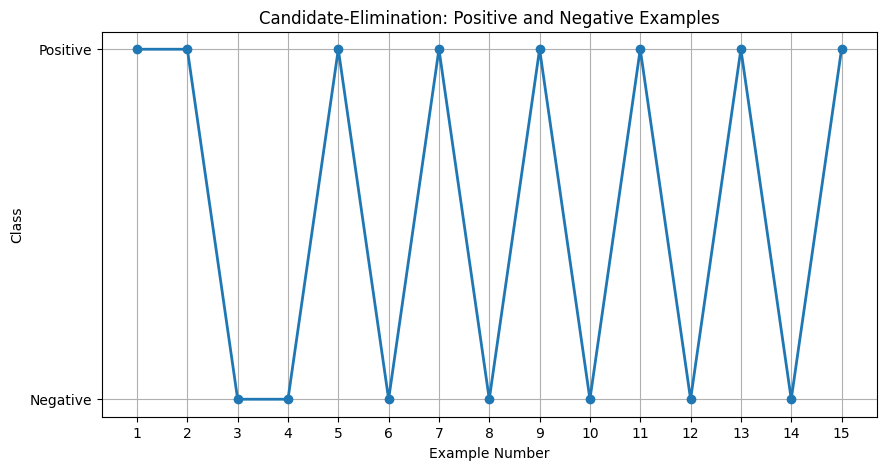

In [2]:
import pandas as pd
import itertools
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("candidate_elimination_dataset.csv")

attributes = list(df.columns[:-1])
target = df.columns[-1]

# Get possible values
values = [sorted(df[col].unique()) for col in attributes]

ANY = "?"

def covers(h, x):
    return all(hv == "?" or hv == xv for hv, xv in zip(h, x))

def more_general_or_equal(h1, h2):
    return all(a == "?" or a == b for a, b in zip(h1, h2))

# Generate hypothesis space
hypothesis_space = list(
    itertools.product(*[v + [ANY] for v in values])
)

# Find version space
version_space = []

for h in hypothesis_space:
    consistent = True

    for _, row in df.iterrows():
        x = tuple(row[col] for col in attributes)
        actual = row[target] == "Yes"
        prediction = covers(h, x)

        if prediction != actual:
            consistent = False
            break

    if consistent:
        version_space.append(h)

# Find most specific hypotheses
S = [
    h for h in version_space
    if not any(
        h != h2 and more_general_or_equal(h, h2)
        for h2 in version_space
    )
]

# Find most general hypotheses
G = [
    h for h in version_space
    if not any(
        h != h2 and more_general_or_equal(h2, h)
        for h2 in version_space
    )
]

print("Final Version Space:")
for h in version_space:
    print(h)

print("\nMost Specific Hypothesis (S):")
for h in S:
    print(h)

print("\nMost General Hypothesis (G):")
for h in G:
    print(h)

# ---------------- GRAPH ----------------

# Convert Yes/No into 1/0
y = df[target].map({"Yes": 1, "No": 0})

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(df) + 1),
    y,
    marker="o",
    linewidth=2
)

plt.yticks([0, 1], ["Negative", "Positive"])
plt.xticks(range(1, len(df) + 1))
plt.xlabel("Example Number")
plt.ylabel("Class")
plt.title("Candidate-Elimination: Positive and Negative Examples")
plt.grid(True)

plt.show()